# Assignment 3

## Shane Fleming

### 11/30/2025

***

#### Q1

In [9]:
import pandas as pd
import numpy as np

df1 = pd.read_excel('city_sales20.xlsx', skiprows=3, skipfooter=4)

#Check the first few rows of the dataframe
df1.head()

,office,2013,2014,2015,2016,2017,2018,2019,2020
0,NY,45,31,34,56,67,45,67,45
1,BOS,34,23,24,26,25,34,26,22
2,MIA,45,81,43,44,41,45,51,41
3,DC,12,13,15,11,11,18,19,20
4,SEA,52,48,47,41,41,42,44,42


***

#### Q2

No, this data set is not set up optimally. The years should not be separate columns, but one column for year, and then there should be another column for sales dollars. Year is actually its own variable, and the current columns are the values for that variable. This data set is wide, and will make it difficult to visualize or transform for analysis. 

***

#### Q3

In [7]:
#Need to use melt to reshape the data
d2 = df1.melt(id_vars='office', var_name='year', value_name='sales')

#Confirm I did the right thing
print(d2)

   office  year  sales
0      NY  2013     45
1     BOS  2013     34
2     MIA  2013     45
3      DC  2013     12
4     SEA  2013     52
5     PHI  2013     43
6     CHI  2013     36
7      NY  2014     31
8     BOS  2014     23
9     MIA  2014     81
10     DC  2014     13
11    SEA  2014     48
12    PHI  2014     39
13    CHI  2014     35
14     NY  2015     34
15    BOS  2015     24
16    MIA  2015     43
17     DC  2015     15
18    SEA  2015     47
19    PHI  2015     38
20    CHI  2015     36
21     NY  2016     56
22    BOS  2016     26
23    MIA  2016     44
24     DC  2016     11
25    SEA  2016     41
26    PHI  2016     38
27    CHI  2016     39
28     NY  2017     67
29    BOS  2017     25
30    MIA  2017     41
31     DC  2017     11
32    SEA  2017     41
33    PHI  2017     33
34    CHI  2017     38
35     NY  2018     45
36    BOS  2018     34
37    MIA  2018     45
38     DC  2018     18
39    SEA  2018     42
40    PHI  2018     35
41    CHI  2018     33
42     NY  

***

#### Q4

In [ ]:
#Filter d2 for years 2014-2020
filtered = d2[(d2['year'] >= 2014) & (d2['year'] <= 2020)]

#Calculate mean sales by office
mean_sales = filtered.groupby('office')['sales'].mean()

#Find the office with the highest mean
highest_mean_office = mean_sales.idxmax()
highest_mean_value = mean_sales.max()

print(f"Office with highest mean sales (2014-2020): {highest_mean_office}")
print(f"Mean sales: {highest_mean_value:.2f}")

Office with highest mean sales (2014-2020): MIA
Mean sales: 49.43


***

#### Q5

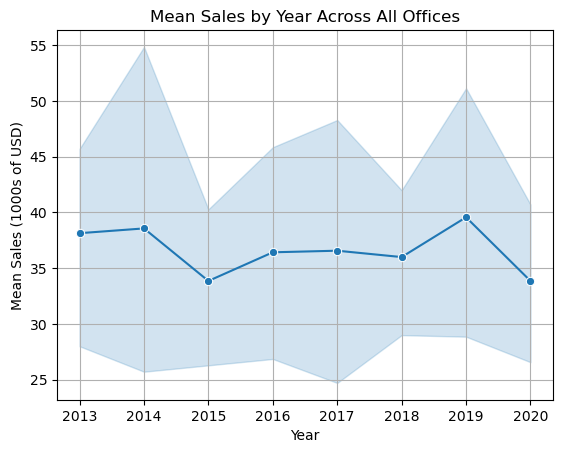

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

#Used seaborn built in estimator to get the mean sales by year
sns.lineplot(data=d2, x='year', y='sales', estimator='mean', marker='o')
plt.xlabel('Year')
plt.ylabel('Mean Sales (1000s of USD)')
plt.title('Mean Sales by Year Across All Offices')
plt.grid(True)
plt.show()

***

#### Q6

<Axes: xlabel='year', ylabel='sales'>

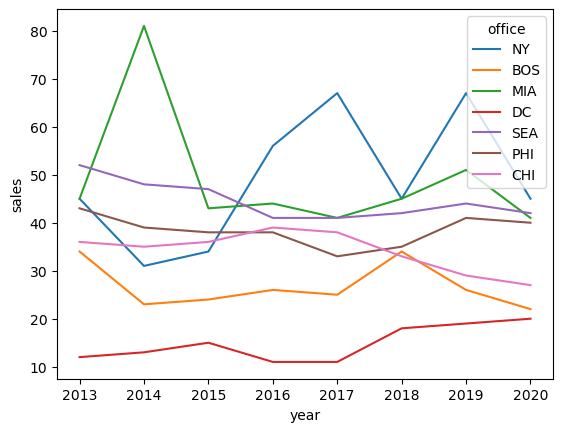

In [24]:
#Super simple line plot with Seaborn

sns.lineplot(data=d2, x='year', y='sales', hue='office')

***

#### Q7

In [ ]:
#Creating the function to ingest new files and clean them

def clean_sales(filename):
    #Ingest a new file
    d1 = pd.read_excel(filename, skiprows=3, skipfooter=4)

    #Drop any rows with missing data
    d1 = d1.dropna()

    #Transform the data
    d2 = d1.melt(id_vars='office', var_name='year', value_name='sales')

    return d2



,office,year,sales
0,NY,2013,45
1,BOS,2013,34
2,MIA,2013,45
3,DC,2013,12
4,SEA,2013,52


***

#### Q8

In [31]:
d21 = clean_sales('city_sales21.xlsx')
d21.tail()

,office,year,sales
58,MIA,2021,74
59,DC,2021,20
60,SEA,2021,37
61,PHI,2021,32
62,CHI,2021,28


****

#### Q9

Max sales office in 2021: MIA with sales of 74


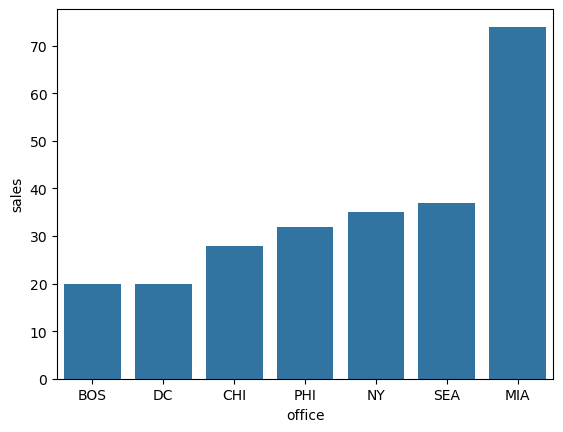

In [ ]:
#Filter for year 2021 only
d21_2021 = d21[d21['year'] == 2021]

#Sort by sales ascending
d21_2021 = d21_2021.sort_values(by='sales')

#Use seaborn to create a bar plot of sales by office for 2021
sns.barplot(data=d21_2021, x='office', y='sales')

#Figure out the office with the highest sales in 2021
max_sales_office = d21_2021.loc[d21_2021['sales'].idxmax()]

#Print it out nicely
print(f'Max sales office in 2021: {max_sales_office["office"]} with sales of {max_sales_office["sales"]}')

***

#### Q10

In [ ]:
#Sort the df by sales descending and then collect the top 5
top_5 = d21.sort_values(by='sales', ascending=False).head()

#Print them out nice-ish
print(f"Top 5 year city:\n{top_5[['year','office', 'sales']]}")

Top 5 year city:
    year office  sales
9   2014    MIA     81
58  2021    MIA     74
42  2019     NY     67
28  2017     NY     67
21  2016     NY     56
